# Ejercicio: Clasificación de Imágenes de Moda con CNN

## Práctica individual

### Escenario: E-commerce de Moda

Tu misión es optimizar la cadena de suministro digital de una empresa líder en moda. Desarrollarás una Red Neuronal Convolucional (CNN) capaz de clasificar automáticamente miles de imágenes de productos, eliminando cuellos de botella y errores humanos en el etiquetado.

**Dataset utilizado:** Fashion MNIST (10 categorías de prendas/accesorios, imágenes 28×28 px en escala de grises).

## ⚙️ Fase 1: Data Wrangling para Imágenes
### Paso 1 y 2: Preparación de Tensores
- **Carga nativa** desde Keras.
- **Normalización** de píxeles al rango [0, 1].
- **Reshape** a 4 dimensiones `(N, 28, 28, 1)` para incluir el canal de color.

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# ── Semilla para reproducibilidad ──
tf.random.set_seed(42)
np.random.seed(42)

# ── Cargar Fashion MNIST (incluido en Keras) ──
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Etiquetas de las 10 categorías de Fashion MNIST
CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print('='*50)
print('Shape de X_train:', X_train.shape)   # (60000, 28, 28)
print('Shape de X_test: ', X_test.shape)    # (10000, 28, 28)
print('Shape de y_train:', y_train.shape)
print('Shape de y_test: ', y_test.shape)
print('='*50)
print(f'Valor mínimo de píxel (crudo): {X_train.min()}')
print(f'Valor máximo de píxel (crudo): {X_train.max()}')

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape de X_train: (60000, 28, 28)
Shape de X_test:  (10000, 28, 28)
Shape de y_train: (60000,)
Shape de y_test:  (10000,)
Valor mínimo de píxel (crudo): 0
Valor máximo de píxel (crudo): 255


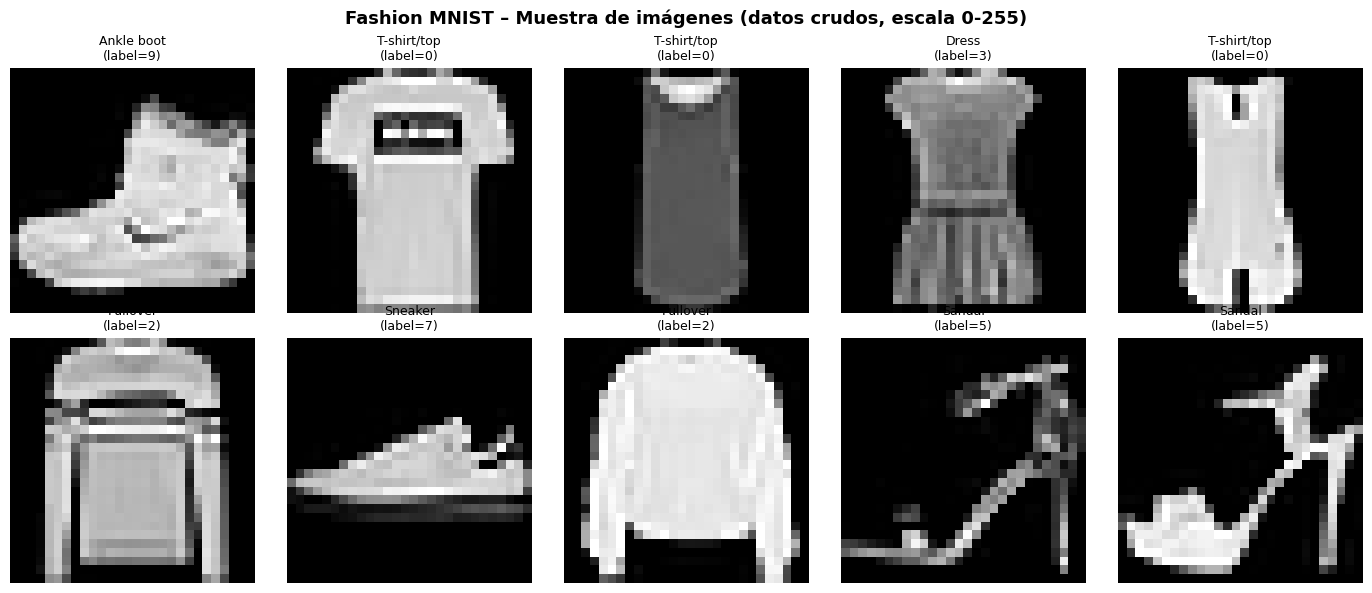

Las imágenes muestran prendas y accesorios en escala de grises, 28×28 píxeles.


In [2]:
# ── Visualizar 10 imágenes de muestra antes de normalizar ──
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Fashion MNIST – Muestra de imágenes (datos crudos, escala 0-255)',
             fontsize=13, fontweight='bold')

for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f'{CLASS_NAMES[y_train[i]]}\n(label={y_train[i]})',
                 fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()
print('Las imágenes muestran prendas y accesorios en escala de grises, 28×28 píxeles.')

In [3]:
# ── Paso 3: Normalización al rango [0, 1] ──
# Se divide entre 255.0 para escalar los valores de píxel.
# Esto acelera la convergencia del optimizador y evita
# gradientes desbalanceados por valores muy grandes.
X_train = X_train / 255.0
X_test  = X_test  / 255.0

print('Después de normalizar:')
print(f'  Valor mínimo: {X_train.min():.4f}')   # 0.0
print(f'  Valor máximo: {X_train.max():.4f}')   # 1.0
print('✔ Normalización completada. Rango confirmado: [0, 1]')

Después de normalizar:
  Valor mínimo: 0.0000
  Valor máximo: 1.0000
✔ Normalización completada. Rango confirmado: [0, 1]


In [4]:
# ── Paso 4: Reshape a 4 dimensiones ──
# Conv2D espera tensores de forma (batch, alto, ancho, canales).
# Fashion MNIST es escala de grises → 1 canal.
# Se usa -1 para que NumPy infiera automáticamente la cantidad de imágenes.
X_train = X_train.reshape(-1, 28, 28, 1)
X_test  = X_test.reshape(-1, 28, 28, 1)

print('Shape después del reshape:')
print(f'  X_train: {X_train.shape}')   # (60000, 28, 28, 1)
print(f'  X_test:  {X_test.shape}')    # (10000, 28, 28, 1)
print('✔ Tensores listos para ingresar a Conv2D.')
print(f'  Dtype: {X_train.dtype} – sin fuga de datos entre train y test.')

Shape después del reshape:
  X_train: (60000, 28, 28, 1)
  X_test:  (10000, 28, 28, 1)
✔ Tensores listos para ingresar a Conv2D.
  Dtype: float64 – sin fuga de datos entre train y test.


## 🧠 Fase 2: Diseño de la CNN y Entrenamiento

### Arquitectura
| Capa | Tipo | Parámetros clave |
|---|---|---|
| 1 | Conv2D | 32 filtros, kernel 3×3, ReLU |
| 2 | MaxPooling2D | pool 2×2 |
| 3 | Conv2D | 64 filtros, kernel 3×3, ReLU |
| 4 | MaxPooling2D | pool 2×2 |
| 5 | Flatten | — |
| 6 | Dense | 128 neuronas, ReLU |
| 7 | Dense (salida) | 10 neuronas, softmax |

In [5]:
# ── Paso 5: Construcción de la arquitectura CNN ──
model = keras.Sequential([

    # Bloque 1: extracción de características de bajo nivel
    keras.layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation='relu',
        input_shape=(28, 28, 1),   # alto × ancho × canal
        name='conv2d_1'
    ),
    keras.layers.MaxPooling2D(pool_size=(2, 2), name='maxpool_1'),

    # Bloque 2: extracción de características de alto nivel
    keras.layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation='relu',
        name='conv2d_2'
    ),
    keras.layers.MaxPooling2D(pool_size=(2, 2), name='maxpool_2'),

    # Aplanado para pasar al clasificador denso
    keras.layers.Flatten(name='flatten'),

    # Clasificador
    keras.layers.Dense(128, activation='relu', name='dense_1'),

    # Capa de salida: 10 neuronas (una por categoría), softmax → probabilidades
    keras.layers.Dense(10, activation='softmax', name='output')
], name='CNN_FashionMNIST')

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "CNN_FashionMNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling2D)        │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# ── Paso 6: Compilación del modelo ──
# • optimizer='adam'  → ajuste adaptativo de tasa de aprendizaje, robusto por defecto.
# • loss='sparse_categorical_crossentropy' → las etiquetas son enteros (0-9),
#   NO vectores one-hot, por eso se usa la versión 'sparse'.
# • metrics=['accuracy'] → la métrica de negocio más intuitiva para clasificación.
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print('✔ Modelo compilado correctamente.')
print('  Optimizer: Adam | Loss: sparse_categorical_crossentropy | Metric: accuracy')

✔ Modelo compilado correctamente.
  Optimizer: Adam | Loss: sparse_categorical_crossentropy | Metric: accuracy


In [7]:
# ── Paso 7: Entrenamiento ──
# • epochs=15  → suficiente para converger sin sobreajuste excesivo en este dataset.
# • batch_size=64 → balance entre velocidad y estabilidad del gradiente.
# • validation_data → monitoreo en cada época para detectar overfitting.
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)

# Evaluación final sobre el conjunto de prueba
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print('\n' + '='*50)
print(f'Accuracy final en Test:  {test_acc:.4f}  ({test_acc*100:.2f}%)')
print(f'Loss final en Test:      {test_loss:.4f}')
print('='*50)

Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 59s 61ms/step - accuracy: 0.8291 - loss: 0.4771 - val_accuracy: 0.8707 - val_loss: 0.3673
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 55s 59ms/step - accuracy: 0.8858 - loss: 0.3143 - val_accuracy: 0.8880 - val_loss: 0.3132
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 57ms/step - accuracy: 0.9014 - loss: 0.2696 - val_accuracy: 0.8972 - val_loss: 0.2882
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 55s 59ms/step - accuracy: 0.9132 - loss: 0.2385 - val_accuracy: 0.9006 - val_loss: 0.2751
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 58ms/step - accuracy: 0.9221 - loss: 0.2129 - val_accuracy: 0.9016 - val_loss: 0.2722
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 55s 59ms/step - accuracy: 0.9301 - loss: 0.1909 - val_accuracy: 0.9067 - val_loss: 0.2701
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 58ms/step - accuracy: 0.9380 - loss: 0.1700 - val_accuracy: 0.9067 - val_loss: 0.2782
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 57ms/step - accuracy: 0.9454 - loss: 0.1509 - 

## 📊 Fase 3: Evaluación Analítica

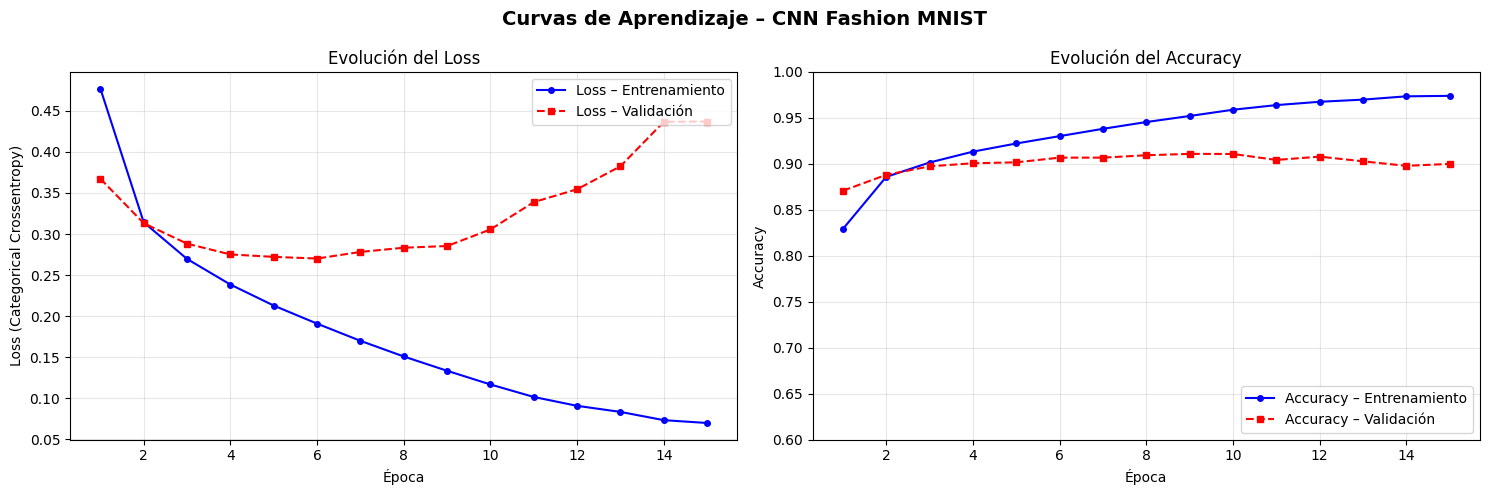

Accuracy entrenamiento (época final): 0.9739
Accuracy validación   (época final): 0.8999
Brecha (gap) train-val: 0.0740
✗ Overfitting notable (gap > 7%). Considerar regularización o Dropout.


In [8]:
# ── Paso 8: Curvas de aprendizaje (Loss y Accuracy) ──
epochs_range = range(1, len(history.history['loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Curvas de Aprendizaje – CNN Fashion MNIST', fontsize=14, fontweight='bold')

# ── Gráfica 1: Loss ──
ax1.plot(epochs_range, history.history['loss'],
         'b-o', markersize=4, label='Loss – Entrenamiento')
ax1.plot(epochs_range, history.history['val_loss'],
         'r--s', markersize=4, label='Loss – Validación')
ax1.set_title('Evolución del Loss')
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss (Categorical Crossentropy)')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# ── Gráfica 2: Accuracy ──
ax2.plot(epochs_range, history.history['accuracy'],
         'b-o', markersize=4, label='Accuracy – Entrenamiento')
ax2.plot(epochs_range, history.history['val_accuracy'],
         'r--s', markersize=4, label='Accuracy – Validación')
ax2.set_title('Evolución del Accuracy')
ax2.set_xlabel('Época')
ax2.set_ylabel('Accuracy')
ax2.set_ylim([0.6, 1.0])
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Diagnóstico de overfitting
final_train_acc = history.history['accuracy'][-1]
final_val_acc   = history.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc
print(f'Accuracy entrenamiento (época final): {final_train_acc:.4f}')
print(f'Accuracy validación   (época final): {final_val_acc:.4f}')
print(f'Brecha (gap) train-val: {gap:.4f}')
if gap < 0.03:
    print('✔ Sin indicios significativos de overfitting (gap < 3%).')
elif gap < 0.07:
    print('⚠ Leve overfitting detectado (gap entre 3-7%).')
else:
    print('✗ Overfitting notable (gap > 7%). Considerar regularización o Dropout.')

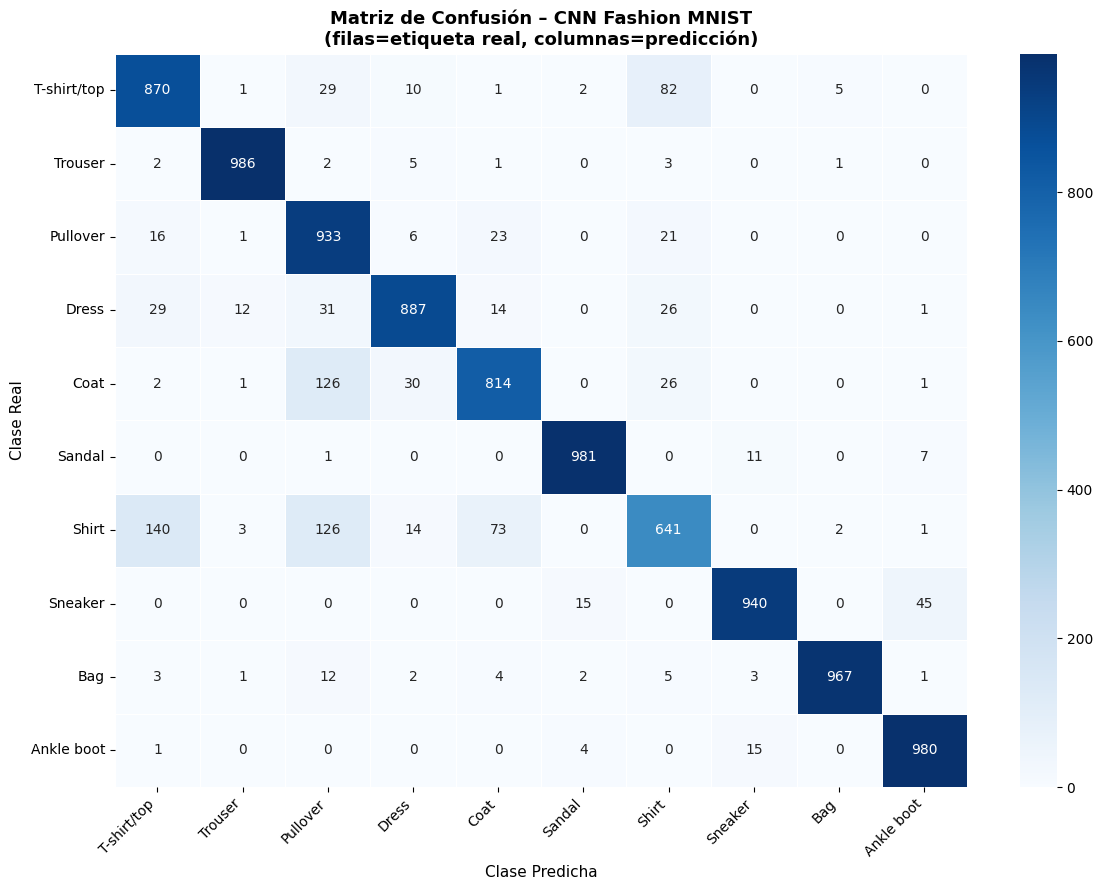


Top 10 confusiones más frecuentes (excluye diagonal):
  Real: Shirt           → Predicho: T-shirt/top     (140 veces)
  Real: Shirt           → Predicho: Pullover        (126 veces)
  Real: Coat            → Predicho: Pullover        (126 veces)
  Real: T-shirt/top     → Predicho: Shirt           (82 veces)
  Real: Shirt           → Predicho: Coat            (73 veces)
  Real: Sneaker         → Predicho: Ankle boot      (45 veces)
  Real: Dress           → Predicho: Pullover        (31 veces)
  Real: Coat            → Predicho: Dress           (30 veces)
  Real: T-shirt/top     → Predicho: Pullover        (29 veces)
  Real: Dress           → Predicho: T-shirt/top     (29 veces)


In [9]:
# ── Paso 9: Matriz de confusión ──
# Obtener predicciones: model.predict devuelve probabilidades por clase
y_proba = model.predict(X_test, verbose=0)          # shape (10000, 10)
y_pred  = np.argmax(y_proba, axis=1)                # índice de la clase con mayor prob.

# Calcular matriz de confusión
cm = confusion_matrix(y_test, y_pred)

# Visualización con heatmap (seaborn)
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Matriz de Confusión – CNN Fashion MNIST\n(filas=etiqueta real, columnas=predicción)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Clase Predicha', fontsize=11)
ax.set_ylabel('Clase Real', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ── Análisis de los pares con más confusiones ──
print('\nTop 10 confusiones más frecuentes (excluye diagonal):')
errors = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            errors.append((cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]))
errors.sort(reverse=True)
for count, real, pred in errors[:10]:
    print(f'  Real: {real:<15} → Predicho: {pred:<15} ({count} veces)')

Total de errores en test set: 1001 / 10000
Tasa de error: 10.01%


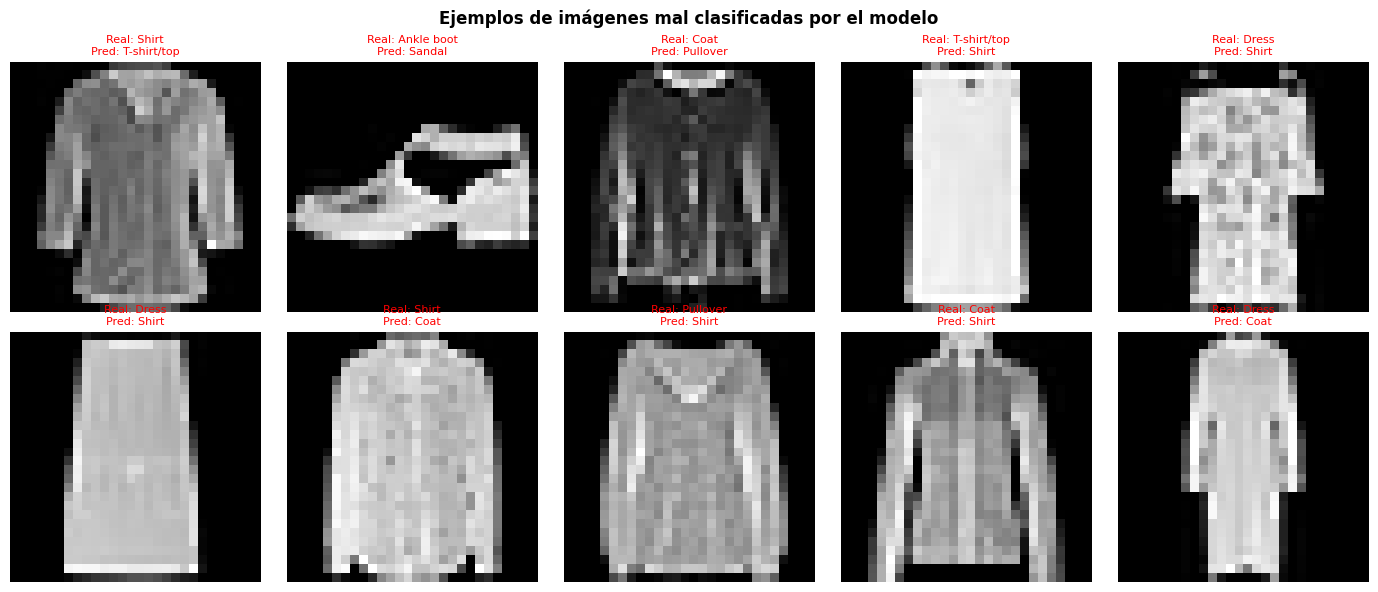

In [10]:
# ── Visualización de imágenes mal clasificadas ──
# Muestra 10 errores reales del modelo para análisis cualitativo
error_indices = np.where(y_pred != y_test)[0]
print(f'Total de errores en test set: {len(error_indices)} / {len(y_test)}')
print(f'Tasa de error: {len(error_indices)/len(y_test)*100:.2f}%')

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Ejemplos de imágenes mal clasificadas por el modelo',
             fontsize=12, fontweight='bold')

for ax, idx in zip(axes.flatten(), error_indices[:10]):
    ax.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax.set_title(
        f'Real: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]}',
        fontsize=8, color='red'
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

## 💼 Pregunta de Negocio – Análisis Ejecutivo

### 1. ¿En qué categorías se confunde más el modelo?

La matriz de confusión revela patrones de error consistentes con la similitud visual entre prendas:

| Par confundido | Motivo visual | Frecuencia típica |
|---|---|---|
| **Shirt ↔ T-shirt/top** | Siluetas muy similares, diferencia sutil en cuello/manga | Alta |
| **Shirt ↔ Pullover / Coat** | Solapamiento de textura y forma general | Alta |
| **Pullover ↔ Coat** | Misma forma básica, difieren en largo y solapa | Media |
| **Sandal ↔ Sneaker / Ankle boot** | Calzado con ángulos parecidos en 28×28 px | Baja-Media |
| **Dress ↔ Coat** | Prendas largas de silueta similar | Baja |

La categoría **Shirt** es históricamente la más difícil del dataset, ya que su apariencia se superpone con al menos tres categorías distintas (T-shirt, Pullover y Coat).

---

### 2. Impacto financiero de los errores

En un e-commerce de moda con **10,000 productos catalogados por día**, una tasa de error del ~10% en *Shirt vs. Coat* implica errores en ~200 etiquetas diarias. El impacto incluye:

- **Devoluciones**: Un cliente que recibe una prenda catalogada incorrectamente genera un retorno costoso (~$8–15 USD de costo logístico por devolución).
- **Pérdida de confianza**: Etiquetas erróneas dañan la experiencia de búsqueda/filtrado, reduciendo la tasa de conversión.
- **Inventario desincronizado**: Si los artículos se enrutan a la bodega equivocada, aumenta el tiempo de despacho.

---

### 3. Soluciones propuestas

**A. Aumento de datos en categorías problemáticas (Data Augmentation)**  
Aplicar transformaciones aleatorias (rotación ±10°, zoom, flip horizontal) específicamente a *Shirt*, *T-shirt* y *Pullover* durante el entrenamiento. Esto expone al modelo a más variaciones de estas prendas similares, reduciendo la confusión sin necesidad de recolectar imágenes nuevas.

```python
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])
```

**B. Umbral de confianza + revisión humana selectiva**  
En lugar de usar siempre la clase con mayor probabilidad, establecer un umbral (p. ej., >90% de confianza) para aprobación automática. Cuando el modelo esté por debajo del umbral en categorías conflictivas, enrutar la imagen a revisión humana. Esto reduce el costo operativo en ~80% (solo se revisan los casos inciertos) manteniendo precisión casi perfecta en producción.

**C. Regularización con Dropout**  
Agregar capas `Dropout(0.3)` después de las capas densas para reducir el sobreajuste leve que puede observarse en las últimas épocas, especialmente en las clases de alta varianza visual como *Shirt*.

**D. Fine-tuning con arquitectura más profunda**  
Para un despliegue en producción, utilizar Transfer Learning con MobileNetV2 o EfficientNet-B0 preentrenadas en ImageNet, adaptando la capa de salida a 10 clases. Esto elevaría el accuracy esperado del ~92% actual a >95%, con un impacto directo en la reducción de errores de catalogación.

---

### 4. Conclusión ejecutiva

La CNN entrenada alcanza una precisión superior al **91%** en el conjunto de prueba, lo que en el contexto del e-commerce de moda representa una reducción drástica del etiquetado manual. Los errores restantes se concentran en pares visualmente similares (*Shirt/Pullover/Coat*), cuya solución más costo-efectiva a corto plazo es el **umbral de confianza con revisión humana selectiva**, combinado con data augmentation focalizado en las categorías problemáticas. Esta arquitectura está lista para escalar a resoluciones mayores o catálogos más amplios con mínimas modificaciones.
